# NumPy y Numba frente a Python puro

Tres problemas resueltos dos veces, una con Python puro y otra vectorizada con NumPy y compilada con Numba (`@njit`), con medición de tiempos para distintos tamaños de entrada:

1. Valor esperado de una variable aleatoria discreta.
2. Juego del caos (triángulo de Sierpinski).
3. Ventas de un concurso de hamburguesas a partir de una matriz de conteos.

Autores: Santiago Castellanos, Catalina Gutiérrez y Camilo Millán.

In [1]:
import random
import timeit
from typing import List, Tuple

import numpy as np
import matplotlib.pyplot as plt
from numba import njit, float64

np.random.seed(42)
random.seed(42)

def medir(funcion, *args, repeticiones=1000):
    """Tiempo medio por llamada en microsegundos (mejor de 5 rondas)."""
    funcion(*args)  # calentamiento: incluye la compilación de Numba
    tiempos = timeit.repeat(lambda: funcion(*args), number=repeticiones, repeat=5)
    return min(tiempos) / repeticiones * 1e6

def comparar(nombre, f_python, args_python, f_numba, args_numba, repeticiones=1000):
    t_py = medir(f_python, *args_python, repeticiones=repeticiones)
    t_nb = medir(f_numba, *args_numba, repeticiones=repeticiones)
    print(f'{nombre}: Python {t_py:,.2f} µs | NumPy + Numba {t_nb:,.2f} µs | {t_py / t_nb:,.1f}× más rápido')
    return t_py / t_nb

Los tiempos dependen de la máquina; lo que interesa es la relación entre las dos versiones. En cada medición se llama una vez a la función antes de cronometrar, para no contar el tiempo de compilación de Numba.

## 1. Valor esperado

$$E[X] = \sum_i P(x_i)\,x_i$$

La versión NumPy no usa ciclos: multiplica los dos arreglos elemento a elemento y suma.

In [2]:
def valor_esperado_python(vals: List[float], probs: List[float]) -> float:
    return sum(a * b for a, b in zip(vals, probs))

@njit(float64(float64[:], float64[:]))
def valor_esperado_numba(vals, probs):
    return np.sum(vals * probs)

vals = [1.0, 2.0, 3.0, 4.0]
probs = [0.3, 0.2, 0.3, 0.2]
print('Python:', valor_esperado_python(vals, probs))
print('Numba: ', valor_esperado_numba(np.array(vals), np.array(probs)))

Python: 2.4
Numba:  2.4


In [3]:
for n in (4, 1_000, 100_000):
    v = np.random.uniform(1, 9, n)
    p = np.random.dirichlet(np.ones(n))
    comparar(f'n = {n:>7,}', valor_esperado_python, (v.tolist(), p.tolist()),
             valor_esperado_numba, (v, p), repeticiones=200)

n =       4: Python 0.41 µs | NumPy + Numba 0.24 µs | 1.7× más rápido
n =   1,000: Python 32.82 µs | NumPy + Numba 1.22 µs | 26.9× más rápido


n = 100,000: Python 3,306.40 µs | NumPy + Numba 159.88 µs | 20.7× más rápido


## 2. Juego del caos

Desde un punto al azar, se elige uno de los tres vértices de un triángulo y se avanza a la mitad del camino; repetido muchas veces, los puntos dibujan el triángulo de Sierpinski. Cada punto depende del anterior, así que el ciclo no se puede vectorizar del todo: Numba compila el ciclo, y los vértices elegidos se generan de una vez con NumPy.

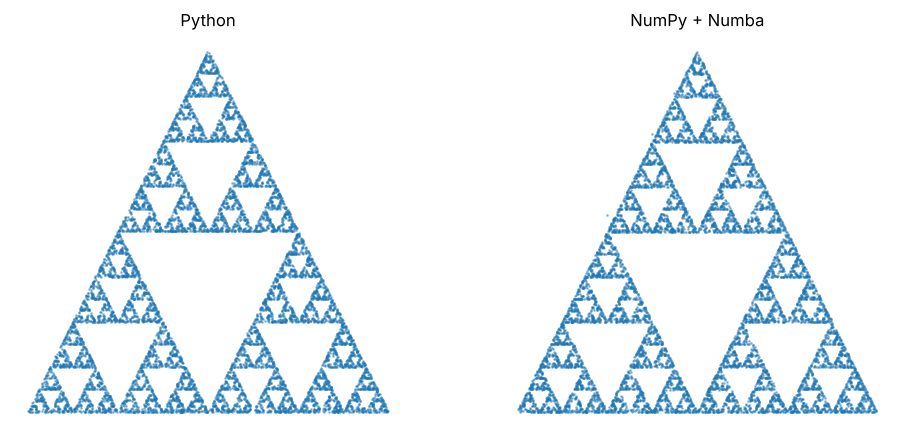

In [4]:
VERTICES = np.array([[0.0, 0.0], [0.5, 1.0], [1.0, 0.0]])

def caos_python(n: int) -> List[Tuple[float, float]]:
    vertices = [(0, 0), (0.5, 1), (1, 0)]
    p = (random.random(), random.random())
    puntos = []
    for _ in range(n):
        v = random.choice(vertices)
        p = ((v[0] + p[0]) / 2, (v[1] + p[1]) / 2)
        puntos.append(p)
    return puntos

@njit
def caos_numba(n):
    puntos = np.zeros((n, 2))
    elegidos = np.random.randint(0, 3, n)
    puntos[0] = np.random.rand(2)
    for i in range(n - 1):
        puntos[i + 1] = (puntos[i] + VERTICES[elegidos[i]]) / 2
    return puntos

fig, ejes = plt.subplots(1, 2, figsize=(10, 4.5))
for eje, (titulo, pts) in zip(ejes, [('Python', np.array(caos_python(10_000))),
                                     ('NumPy + Numba', caos_numba(10_000))]):
    eje.scatter(pts[:, 0], pts[:, 1], s=1, alpha=0.4)
    eje.set_title(titulo)
    eje.set_aspect('equal')
    eje.axis('off')
plt.tight_layout()
plt.show()

In [5]:
for n in (1_000, 10_000, 100_000):
    comparar(f'n = {n:>7,}', caos_python, (n,), caos_numba, (n,), repeticiones=20)

n =   1,000: Python 276.96 µs | NumPy + Numba 41.48 µs | 6.7× más rápido


n =  10,000: Python 3,123.76 µs | NumPy + Numba 489.06 µs | 6.4× más rápido


n = 100,000: Python 30,113.58 µs | NumPy + Numba 4,102.81 µs | 7.3× más rápido


## 3. Concurso de hamburguesas

Un restaurante regala la comida a quien se coma más de 10 hamburguesas; los demás pagan lo que comieron (pollo 15.000, carne 17.000, pescado 20.000). Con una matriz de conteos (una fila por cliente, una columna por tipo), se calculan los ingresos del evento. La versión NumPy reemplaza los dos ciclos por una suma por filas, un producto matricial y una máscara.

In [6]:
def ventas_python(conteos) -> float:
    precios = [15_000, 17_000, 20_000]
    total = 0
    for cliente in range(conteos.shape[0]):
        unidades = sum(conteos[cliente, j] for j in range(conteos.shape[1]))
        if unidades <= 10:
            total += sum(a * b for a, b in zip(precios, conteos[cliente]))
    return total

@njit(float64(float64[:, ::1]))
def ventas_numba(conteos):
    precios = np.array([15_000.0, 17_000.0, 20_000.0])
    return np.sum(np.where(conteos.sum(axis=1) <= 10, conteos @ precios, 0.0))

conteos = np.array([[3, 2, 3], [5, 5, 1], [10, 0, 0], [1, 1, 1], [0, 11, 0], [0, 0, 15]])
print('Python:', ventas_python(conteos))
print('Numba: ', ventas_numba(conteos.astype(np.float64)))

Python: 341000
Numba:  341000.0


In [7]:
for n in (6, 1_000, 100_000):
    c = np.random.randint(0, 16, size=(n, 3))
    comparar(f'{n:>7,} clientes', ventas_python, (c,), ventas_numba, (c.astype(np.float64),),
             repeticiones=5 if n == 100_000 else 200)

      6 clientes: Python 5.47 µs | NumPy + Numba 0.79 µs | 6.9× más rápido


  1,000 clientes: Python 681.58 µs | NumPy + Numba 5.60 µs | 121.7× más rápido


100,000 clientes: Python 68,828.24 µs | NumPy + Numba 661.21 µs | 104.1× más rápido


## Conclusiones

- Con entradas muy pequeñas (4 valores, 6 clientes) la diferencia es mínima: el costo fijo de llamar a la función pesa más que el cálculo.
- Cuando el problema se puede expresar como operaciones sobre arreglos completos, la ganancia crece con el tamaño: en el valor esperado la versión compilada es unas 20 veces más rápida, y en las hamburguesas, donde se eliminan dos ciclos anidados, más de 100 veces.
- El juego del caos gana menos (unas 7 veces) porque cada punto depende del anterior: el ciclo no desaparece, solo se compila.
- La aceleración depende de cuánto del trabajo se pueda sacar de los ciclos de Python, no solo de usar Numba.